# 01 · Exploration du dataset ACC

Premier tour d'horizon de la base **Allergen Chip Challenge** : 4 271 patients, 15 colonnes cliniques et 241 colonnes d'IgE.

L'objectif est de comprendre ce qu'il y a dans les données avant toute modélisation :
- qui sont les patients (âge, sexe, région, type de puce) ;
- quelle quantité d'information clinique est réellement disponible ;
- à quoi ressemblent les mesures d'IgE et quelles sensibilisations sont fréquentes.

> Pré-requis : `uv sync` puis `uv run acc-download` à la racine du projet.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from acc.data import load_raw, split_columns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_columns", 30)

## 1. Chargement

`load_raw()` gère le format du CSV (séparateur `;`, décimales `,`). Les colonnes cliniques sont gardées en texte, car certaines contiennent plusieurs codes à la fois (ex. `"1,3"`).

In [2]:
df = load_raw()
clinical_cols, ige_cols = split_columns(df)

print(f"{df.shape[0]} patients, {len(clinical_cols)} clinical columns, {len(ige_cols)} IgE columns")
df[clinical_cols].head()

4271 patients, 15 clinical columns, 241 IgE columns


,Patient_ID,Chip_Type,Age,Gender,Blood_Month_sample,French_Residence_Department,French_Region,Rural_or_urban_area,Sensitization,Treatment_of_rhinitis,Treatment_of_athsma,Age_of_onsets,Skin_Symptoms,General_cofactors,Treatment_of_atopic_dematitis
0,FHB0001,ISAC_V1,21.0,1,11,deptY,regionB,9,1,9,9,9,9,0,9
1,FHB0002,ISAC_V1,45.0,0,12,deptY,regionB,9,1,9,9,9,9,0,9
2,FHB0003,ISAC_V1,18.0,1,1,deptY,regionB,9,0,2,9,0,9,5,9
3,FHB0004,ISAC_V1,19.0,0,1,deptY,regionB,9,1,9,9,9,9,0,9
4,FHB0005,ISAC_V1,28.0,0,1,deptY,regionB,9,1,9,9,9,9,0,9


## 2. Les colonnes cliniques

D'après les dictionnaires fournis (`dictionnaire-acc-english.pdf` et `acc-dictionnaire-final.xls`) :

| Colonne | Signification |
|---|---|
| `Chip_Type` | Puce utilisée : ISAC v1, ISAC v2 ou ALEX |
| `Age`, `Gender` | Âge, sexe (1 = masculin, 0 = féminin) |
| `Blood_Month_sample` | Mois de la prise de sang |
| `French_Residence_Department`, `French_Region` | Localisation (anonymisée) |
| `Rural_or_urban_area` | 0 = rural, 1 = urbain |
| `Sensitization` | Le patient est sensibilisé à au moins un allergène |
| `Treatment_of_rhinitis`, `Treatment_of_athsma`, `Treatment_of_atopic_dematitis` | Niveau de traitement (0 = aucun) |
| `Age_of_onsets` | Tranche d'âge d'apparition de l'allergie alimentaire |
| `Skin_Symptoms` | Symptômes cutanés (0 = non, 1 = oui) |
| `General_cofactors` | Cofacteurs (effort, AINS, alcool, animaux…) |

Dans presque toutes ces colonnes, le code **`9` signifie « non renseigné »**. Pour l'exploration, on le remplace par une vraie valeur manquante.

In [3]:
coded_cols = [
    "Rural_or_urban_area", "Treatment_of_rhinitis", "Treatment_of_athsma",
    "Age_of_onsets", "Skin_Symptoms", "General_cofactors", "Treatment_of_atopic_dematitis",
]

clin = df[clinical_cols].copy()
clin[coded_cols] = clin[coded_cols].replace("9", np.nan)

### Données cliniques manquantes

Quelle part des patients a une valeur renseignée pour chaque variable ?

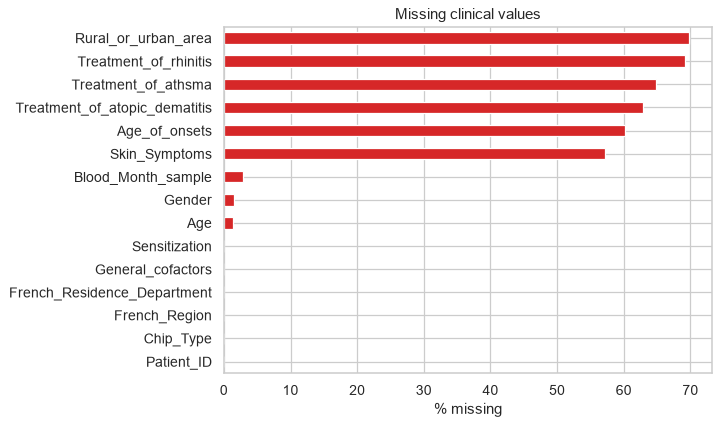

In [4]:
missing = clin.isna().mean().sort_values() * 100

ax = missing.plot.barh(figsize=(7, 5), color="tab:red")
ax.set_xlabel("% missing")
ax.set_title("Missing clinical values")
plt.show()

## 3. Qui sont les patients ?

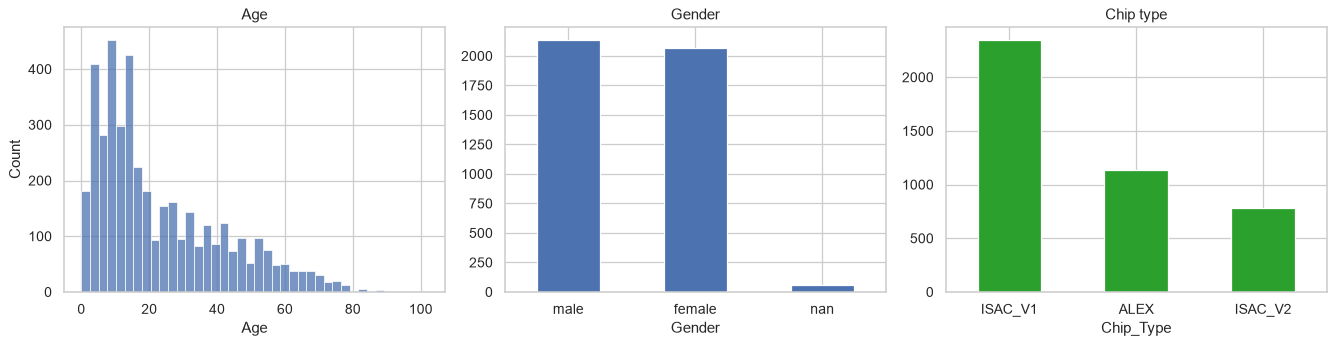

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["Age"], bins=40, ax=axes[0])
axes[0].set_title("Age")

df["Gender"].map({"1": "male", "0": "female"}).value_counts(dropna=False).plot.bar(ax=axes[1])
axes[1].set_title("Gender")

df["Chip_Type"].value_counts().plot.bar(ax=axes[2], color="tab:green")
axes[2].set_title("Chip type")

for ax in axes[1:]:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

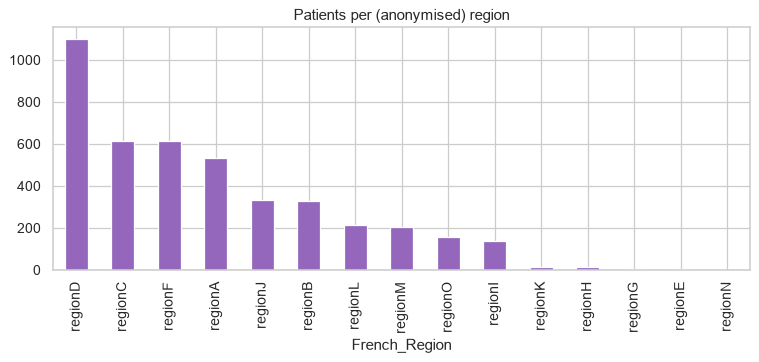

In [6]:
ax = df["French_Region"].value_counts().plot.bar(figsize=(10, 3.5), color="tab:purple")
ax.set_title("Patients per (anonymised) region")
plt.show()

## 4. Le type de puce, une variable centrale

Les trois puces ne mesurent **pas les mêmes allergènes**. Une valeur manquante dans une colonne IgE veut donc souvent dire « allergène absent de cette puce », pas « mesure ratée ».

In [7]:
coverage = df.groupby("Chip_Type")[ige_cols].apply(lambda g: g.notna().mean())
n_measured = (coverage > 0.5).sum(axis=1).rename("allergens measured")
n_measured.to_frame()

,allergens measured
Chip_Type,
ALEX,223
ISAC_V1,112
ISAC_V2,112


In [8]:
shared = coverage.columns[(coverage > 0.5).all()]
print(f"{len(shared)} allergens are measured on all three chips")

91 allergens are measured on all three chips


Les puces n'ont pas non plus été utilisées sur les mêmes patients : comparons l'âge selon la puce.

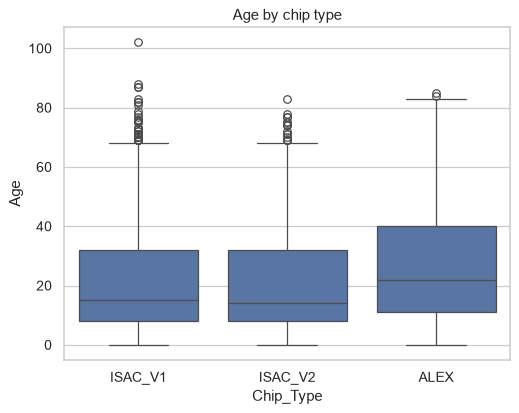

,count,mean,std,min,25%,50%,75%,max
Chip_Type,,,,,,,,
ALEX,1139.0,26.8,19.4,0.0,11.0,22.0,40.0,85.0
ISAC_V1,2351.0,21.7,17.9,0.0,8.0,15.0,32.0,102.0
ISAC_V2,720.0,21.7,18.9,0.0,8.0,14.0,32.0,83.0


In [9]:
ax = sns.boxplot(data=df, x="Chip_Type", y="Age", order=["ISAC_V1", "ISAC_V2", "ALEX"])
ax.set_title("Age by chip type")
plt.show()

df.groupby("Chip_Type")["Age"].describe().round(1)

## 5. Les mesures d'IgE

Chaque colonne IgE contient la concentration d'anticorps contre un allergène (kUA/L pour ALEX, ISU pour ISAC). On regarde d'abord la forme des valeurs.

In [10]:
values = df[ige_cols].stack()  # drops NaN (allergen not on the chip)

print(f"Measured values : {len(values)}")
print(f"Exactly zero    : {(values == 0).mean():.1%}")
print(f"Above 0.3       : {(values >= 0.3).mean():.1%}")

Measured values : 1029311
Exactly zero    : 48.4%
Above 0.3       : 6.1%


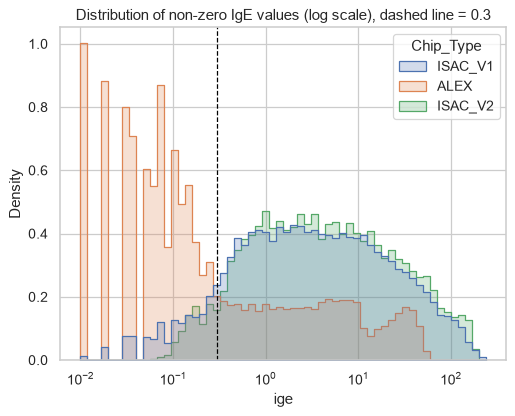

In [11]:
positive = df.melt(id_vars="Chip_Type", value_vars=ige_cols, value_name="ige").query("ige > 0")

ax = sns.histplot(data=positive, x="ige", hue="Chip_Type", log_scale=True,
                  element="step", stat="density", common_norm=False)
ax.axvline(0.3, color="black", ls="--", lw=1)
ax.set_title("Distribution of non-zero IgE values (log scale), dashed line = 0.3")
plt.show()

Deux choses ressortent :
- les valeurs non nulles s'étalent sur **plusieurs ordres de grandeur** : il faudra travailler en échelle log, ou binariser ;
- les puces ne rapportent pas les petites valeurs de la même façon. **ALEX** donne des valeurs entre 0,01 et 0,3, alors que les **ISAC** renvoient 0 sous leur seuil de détection. Les échelles ne sont donc pas directement comparables entre puces.

On utilisera donc plutôt un **seuil de positivité**.

Le seuil usuel est **0,3** (kUA/L pour ALEX, ISU pour ISAC) : au-dessus, le patient est considéré sensibilisé à l'allergène.

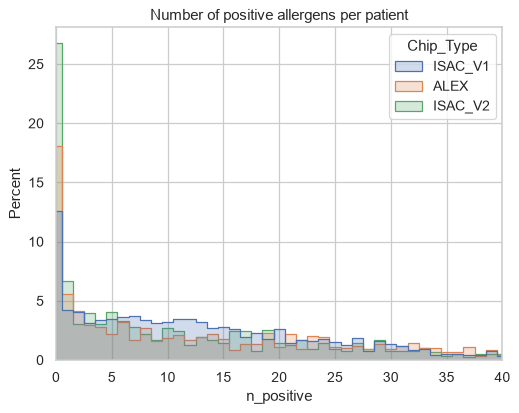

,count,mean,std,min,25%,50%,75%,max
Chip_Type,,,,,,,,
ALEX,1139.0,18.8,21.5,0.0,2.0,12.0,28.5,134.0
ISAC_V1,2351.0,13.8,12.4,0.0,4.0,11.0,21.0,77.0
ISAC_V2,781.0,11.3,13.2,0.0,0.0,6.0,19.0,70.0


In [12]:
THRESHOLD = 0.3

# 1 = positive, 0 = negative, NaN = allergen not on the patient's chip
sensitized = df[ige_cols].ge(THRESHOLD).astype(float).where(df[ige_cols].notna())
df["n_positive"] = sensitized.sum(axis=1)

ax = sns.histplot(data=df, x="n_positive", hue="Chip_Type", discrete=True,
                  stat="percent", common_norm=False, element="step")
ax.set_xlim(0, 40)
ax.set_title("Number of positive allergens per patient")
plt.show()

df.groupby("Chip_Type")["n_positive"].describe().round(1)

### Cohérence avec la variable `Sensitization`

`Sensitization` dit si le patient est sensibilisé à au moins un allergène. On vérifie qu'elle colle au nombre d'allergènes positifs.

In [13]:
pd.crosstab(df["Sensitization"], df["n_positive"].clip(upper=3).astype(int)
            .map({0: "0", 1: "1", 2: "2", 3: "3+"}), margins=True)

n_positive,0,1,2,3+,All
Sensitization,,,,,
0,689,3,0,0,692
1,22,213,167,3177,3579
All,711,216,167,3177,4271


### Les sensibilisations les plus fréquentes

Pour chaque allergène, on calcule la part de patients positifs **parmi ceux pour qui il a été mesuré**.

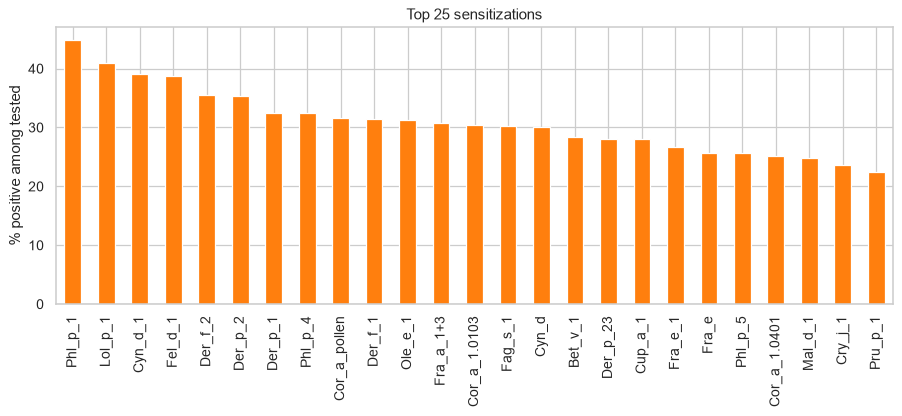

In [14]:
prevalence = sensitized.mean().sort_values(ascending=False) * 100

ax = prevalence.head(25).plot.bar(figsize=(12, 4), color="tab:orange")
ax.set_ylabel("% positive among tested")
ax.set_title("Top 25 sensitizations")
plt.show()

### Co-sensibilisations

Certains allergènes sont souvent positifs ensemble (protéines proches entre espèces, ou même source). La corrélation entre indicateurs de positivité donne une première idée de ces groupes.

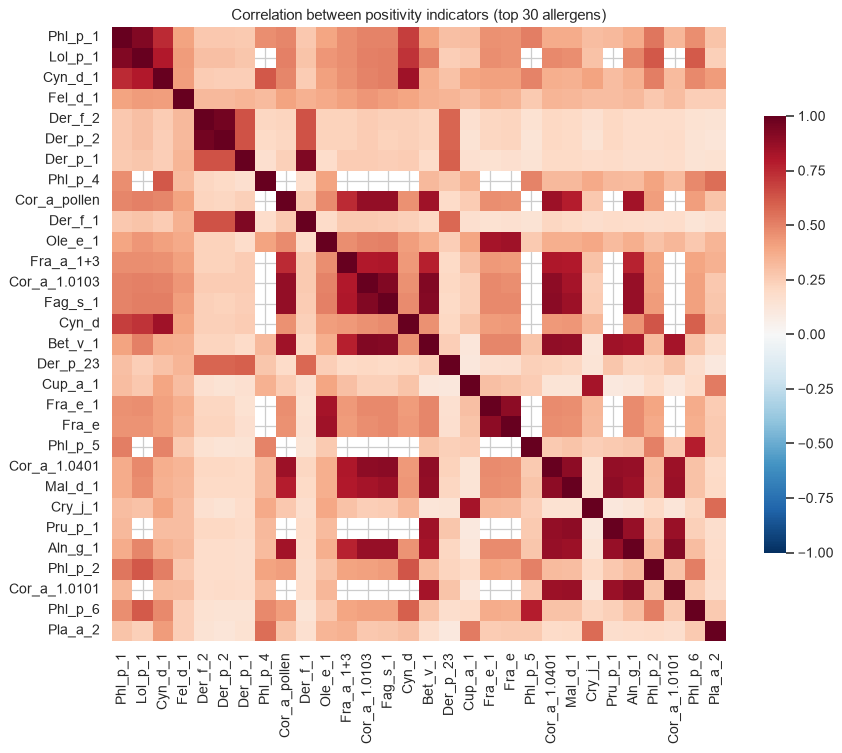

In [15]:
top = prevalence.head(30).index
corr = sensitized[top].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.7})
plt.title("Correlation between positivity indicators (top 30 allergens)")
plt.show()

Des blocs bien nets apparaissent :
- **graminées** : `Phl_p_1`, `Lol_p_1`, `Cyn_d_1` ;
- **acariens** : `Der_p_1/2`, `Der_f_1/2`, `Der_p_23` ;
- un gros bloc **PR-10** qui mélange pollens d'arbres (`Bet_v_1`, `Aln_g_1`, `Fag_s_1`, `Cor_a_1`) et aliments (`Mal_d_1` pomme, `Pru_p_1` pêche). C'est la réactivité croisée pollen–aliment (syndrome oral), en général peu sévère.

Les cases blanches correspondent à des paires d'allergènes qui ne sont **jamais mesurées ensemble** (pas sur la même puce).

## 6. Variables cliniques et type de puce

La disponibilité des données cliniques dépend-elle de la puce (donc, indirectement, du centre et de la période) ?

In [16]:
clin.drop(columns=["Patient_ID", "Chip_Type"]).notna().groupby(df["Chip_Type"]).mean().T.mul(100).round(0)

Chip_Type,ALEX,ISAC_V1,ISAC_V2
Age,100.0,100.0,92.0
Gender,100.0,100.0,92.0
Blood_Month_sample,94.0,100.0,92.0
French_Residence_Department,100.0,100.0,100.0
French_Region,100.0,100.0,100.0
Rural_or_urban_area,23.0,24.0,59.0
Sensitization,100.0,100.0,100.0
Treatment_of_rhinitis,30.0,28.0,39.0
Treatment_of_athsma,38.0,30.0,46.0
Age_of_onsets,44.0,28.0,67.0


Distribution des niveaux de traitement de l'asthme et de la rhinite, parmi les patients renseignés :

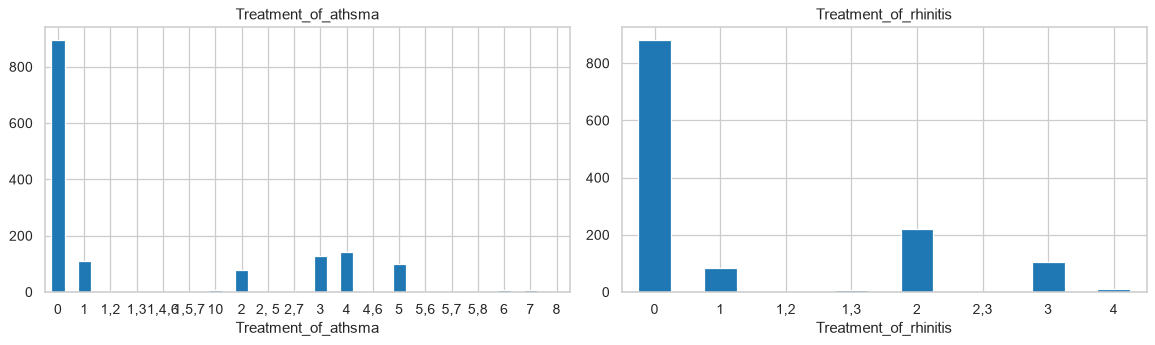

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["Treatment_of_athsma", "Treatment_of_rhinitis"]):
    clin[col].value_counts().sort_index().plot.bar(ax=ax, color="tab:blue")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 7. Ce qu'on retient

**Population**
- Population plutôt **jeune** : âge médian autour de 15 ans, avec beaucoup d'enfants. Les patients ALEX sont un peu plus âgés (médiane 22 ans contre 15).
- Sexe équilibré.
- 84 % des patients sont sensibilisés à au moins un allergène (`Sensitization = 1`). C'est cohérent avec le décompte des IgE ≥ 0,3, à quelques dizaines de patients près.

**Données cliniques**
- Les variables les plus intéressantes pour la sévérité (traitements, symptômes cutanés, âge d'apparition) manquent pour **57 à 70 %** des patients.
- Ce taux dépend de la puce, donc probablement du centre : les patients ISAC v2 sont bien mieux renseignés.
- `General_cofactors` semble complète, mais son code `0` signifie « aucun **connu** » : le manque d'information y est probablement caché.

**IgE**
- Trois puces, trois listes d'allergènes : 112 pour ISAC, 223 pour ALEX, seulement **91 en commun**.
- Les échelles diffèrent aussi : ALEX rapporte des valeurs sous 0,3, alors qu'ISAC met 0.
- Il faudra donc toujours tenir compte de `Chip_Type`, ou se restreindre aux allergènes communs avec un seuil de positivité.
- Les sensibilisations les plus fréquentes sont **respiratoires** : graminées, acariens, chat, pollens d'arbres. Les marqueurs alimentaires sévères (`Ara_h_2`, `Pru_p_3`, `Cor_a_14`…) touchent environ 10 à 16 % des patients.
- Les co-sensibilisations forment des familles cohérentes (graminées, acariens, PR-10). Regrouper les allergènes par **famille de protéines** est une piste naturelle pour la suite.

**Pistes pour la suite**
1. Construire une table « propre » partagée : `9` → NaN, codes multiples → indicatrices, IgE binarisées par puce.
2. Définir un ou plusieurs proxys de sévérité à partir des traitements de l'asthme et de la rhinite.
3. Clustering ou ACP sur les 91 allergènes communs, en vérifiant que les clusters ne reflètent pas simplement le type de puce.